# Aula 12 — Laboratório: limiar de decisão e calibração

**Consultoria Especializada em Ciência de Dados 1**

O modelo já está escolhido. Hoje você faz as duas coisas que faltam para ele virar uma
decisão: **transformar a probabilidade num sim ou num não**, com um corte que se justifica
pelo custo do erro, e **conferir se esse número merece confiança**.

A base é a mesma das Aulas 10 e 11: 850 pacientes, alvo `risco_metabolico == "alto"`,
cerca de 15% de positivos. São 595 pacientes para treino e validação e 255 guardados para o
teste, que você vai tocar **uma vez só**, no fim.

Uma observação sobre os números: as contas deste laboratório usam probabilidades obtidas fora
das dobras, e alguns pacientes ficam bem na fronteira dos cortes baixos. Por isso um ou outro
valor pode diferir do slide na última casa. Isso não é erro: é exatamente o aviso do slide da
curva de custo — **cada degrau da curva é um paciente mudando de lado**, e não se persegue o
mínimo exato.

## Parte 0 — Ambiente, dados e os dois modelos

Dois candidatos da Parte 1 da aula: a **logística**, que foi a escolhida, e a **floresta**,
que volta na Parte 4 porque ordena quase igual e não é igualmente honesta no valor.

As probabilidades de validação vêm de `cross_val_predict`: cada paciente recebe a
probabilidade estimada pelo modelo da dobra em que ele **não** estava no treino. É o que
permite varrer o limiar sem olhar para o teste.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, cross_val_predict,
                                     StratifiedKFold)
from sklearn.metrics import (confusion_matrix, precision_recall_curve,
                             roc_auc_score, log_loss)

pac = pd.read_csv("/content/1_pacientes.csv")
pac["sexo"] = (pac["sexo"] == "M").astype(int)
y = (pac["risco_metabolico"] == "alto").astype(int)
X = pac.drop(columns=["id", "risco_metabolico"])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30,
                                          random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

logistica = Pipeline([("scaler", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=1000))])
floresta  = Pipeline([("scaler", StandardScaler()),
                      ("clf", RandomForestClassifier(n_estimators=200, random_state=42))])

# probabilidade de cada paciente da validação, estimada fora da sua dobra
p_log = cross_val_predict(logistica, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
p_flo = cross_val_predict(floresta,  X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]

print("validação:", len(y_tr), "pacientes |", int(y_tr.sum()), "de alto risco",
      f"({y_tr.mean():.1%})")
print("teste    :", len(y_te), "pacientes |", int(y_te.sum()), "de alto risco")
print("ROC-AUC fora das dobras — logística", round(roc_auc_score(y_tr, p_log), 3),
      "| floresta", round(roc_auc_score(y_tr, p_flo), 3))

validação: 595 pacientes | 90 de alto risco (15.1%)
teste    : 255 pacientes | 38 de alto risco
ROC-AUC fora das dobras — logística 0.957 | floresta 0.944


## Parte 1 — A probabilidade e o corte que veio de fábrica

`predict_proba` devolve a probabilidade; `predict` devolve a classe. A segunda não faz nada
além de comparar a primeira com 0,50 — e esse 0,50 não é uma conclusão do modelo, é um padrão
que alguém escolheu.

### Exemplo — `predict` é uma comparação, e só

In [33]:
modelo = logistica.fit(X_tr, y_tr)
proba = modelo.predict_proba(X_te)[:, 1]
pred  = (proba >= 0.50).astype(int)

print("são o mesmo vetor?", np.array_equal(pred, modelo.predict(X_te)))
print("\nos cinco primeiros pacientes do teste:")
print(pd.DataFrame({"P(risco alto)": proba[:5].round(3), "predict": pred[:5]}))

são o mesmo vetor? True

os cinco primeiros pacientes do teste:
   P(risco alto)  predict
0          0.051        0
1          0.000        0
2          0.853        1
3          0.009        0
4          0.099        0


### Exercício 1 — a tabela de quatro cortes

Escreva uma função `avalia(y_true, p, corte, c_fn=5)` que devolva VN, FP, FN, VP, precisão,
recall e o custo total, com um falso negativo valendo `c_fn` falsos positivos.

Use `confusion_matrix(...).ravel()`, que devolve `(tn, fp, fn, tp)` nessa ordem. Monte a
tabela para os cortes **0,15 · 0,30 · 0,50 · 0,70** sobre `p_log` na validação.

Responda: o que acontece com a precisão e com o recall quando o corte sobe? E qual dos quatro
cortes é o mais caro?

In [34]:
def avalia(y_true, p, corte, c_fn=5):
    tn, fp, fn, tp = confusion_matrix(y_true, (p >= corte).astype(int)).ravel()
    # TODO: precisão, recall e custo (um FN vale c_fn FP)
    # cuidado na precisão: com um corte muito alto ninguém é marcado como positivo,
    # e tp + fp vira zero — devolva 0.0 nesse caso em vez de dividir por zero
    precisao = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall   = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    custo    = fp + c_fn * fn
    return dict(corte=corte, VN=tn, FP=fp, FN=fn, VP=tp,
                precisao=round(precisao, 3), recall=round(recall, 3), custo=custo)

tabela = pd.DataFrame([avalia(y_tr, p_log, c) for c in [0.15, 0.30, 0.50, 0.70]])
tabela

,corte,VN,FP,FN,VP,precisao,recall,custo
0,0.15,444,61,9,81,0.570,0.900,106
1,0.30,468,37,15,75,0.670,0.833,112
2,0.50,486,19,33,57,0.750,0.633,184
3,0.70,500,5,40,50,0.909,0.556,205


### Resposta 1

* **Comportamento da precisão e do recall:** Quando o corte (limiar) sobe, a **precisão aumenta** e o **recall diminui**. Isso acontece porque, ao elevarmos o limiar de decisão, tornamo-nos mais conservadores nas predições positivas. Com isso, cometemos menos erros de falsos positivos (aumentando a precisão), mas acabamos deixando passar mais casos positivos reais (aumentando os falsos negativos, o que derruba o recall).
* **Corte mais caro:** O corte de **0,70** é o mais caro entre os quatro avaliados, gerando um custo total de **205** unidades, devido à alta quantidade de falsos negativos (40 pacientes de alto risco que não seriam detectados).

## Parte 2 — A curva de custo

Quatro cortes é uma amostra. O custo é uma função do limiar, e dá para desenhá-la inteira.

### Exemplo — o custo de um corte só, aberto em parcelas

In [ ]:
r = avalia(y_tr, p_log, 0.50)
print(f"corte 0,50 -> FP = {r['FP']}, FN = {r['FN']}")
print(f"custo = {r['FP']} + 5 x {r['FN']} = {r['FP']} + {5 * r['FN']} = {r['custo']}")

corte 0,50 -> FP = 19, FN = 33
custo = 19 + 5 x 33 = 19 + 165 = 184


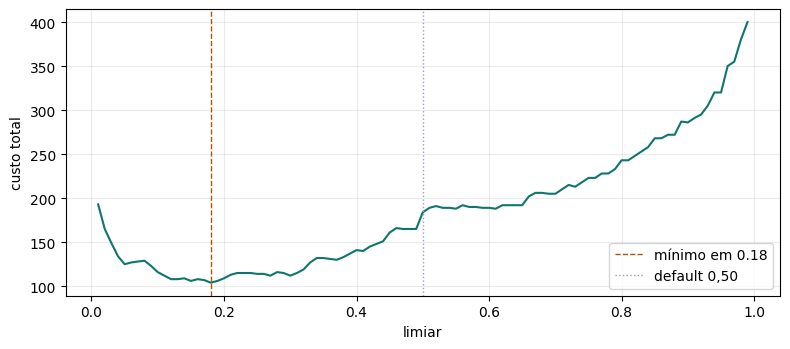

mínimo : corte 0.18  custo 104
default: corte 0,50  custo 184
economia: 43.5%


In [ ]:
cortes = np.round(np.arange(0.01, 1.00, 0.01), 2)

# TODO: custo de cada corte (use a sua função avalia)
custos = [avalia(y_tr, p_log, c)["custo"] for c in cortes]

i_min = int(np.argmin(custos))
c_min, k_min = cortes[i_min], custos[i_min]
k_def = avalia(y_tr, p_log, 0.50)["custo"]

plt.figure(figsize=(8, 3.6))
plt.plot(cortes, custos, color="#0F766E")
plt.axvline(c_min, color="#B45309", ls="--", lw=1, label=f"mínimo em {c_min}")
plt.axvline(0.50, color="#94A3B8", ls=":", lw=1, label="default 0,50")
plt.xlabel("limiar"); plt.ylabel("custo total"); plt.legend(); plt.grid(alpha=.25)
plt.tight_layout(); plt.show()

print(f"mínimo : corte {c_min}  custo {k_min}")
print(f"default: corte 0,50  custo {k_def}")
print(f"economia: {100 * (1 - k_min / k_def):.1f}%")

### Exercício 2 — varrer o limiar e achar o mínimo

Varra o corte de 0,01 a 0,99 em passos de 0,01, guarde o custo de cada um e desenhe a curva.
Marque o mínimo e o default 0,50.

Responda: onde está o mínimo, quanto ele custa, e quanto se economiza em relação ao 0,50?

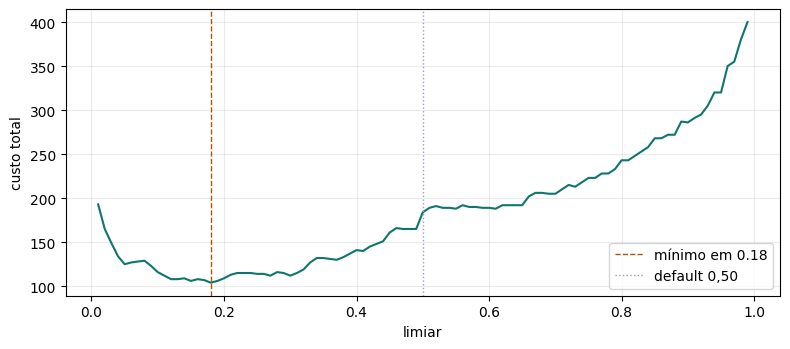

mínimo : corte 0.18  custo 104
default: corte 0,50  custo 184
economia: 43.5%


In [ ]:
cortes = np.round(np.arange(0.01, 1.00, 0.01), 2)

# TODO: custo de cada corte (use a sua função avalia)
custos = [avalia(y_tr, p_log, c)["custo"] for c in cortes]

i_min = int(np.argmin(custos))
c_min, k_min = cortes[i_min], custos[i_min]
k_def = avalia(y_tr, p_log, 0.50)["custo"]

plt.figure(figsize=(8, 3.6))
plt.plot(cortes, custos, color="#0F766E")
plt.axvline(c_min, color="#B45309", ls="--", lw=1, label=f"mínimo em {c_min}")
plt.axvline(0.50, color="#94A3B8", ls=":", lw=1, label="default 0,50")
plt.xlabel("limiar"); plt.ylabel("custo total"); plt.legend(); plt.grid(alpha=.25)
plt.tight_layout(); plt.show()

print(f"mínimo : corte {c_min}  custo {k_min}")
print(f"default: corte 0,50  custo {k_def}")
print(f"economia: {100 * (1 - k_min / k_def):.1f}%")

**Resposta 2:**

* O **custo mínimo** de **104** unidades ocorre no limiar (corte) **0,18**.
* No corte padrão de fábrica (default) de **0,50**, o custo total é de **184**.
* Ao otimizar o limiar para **0,18**, obtém-se uma **economia de 43,5%** nos custos totais de erro em relação ao padrão.

## Parte 3 — Quando a área dá uma meta em vez de um custo

Nem todo cliente sabe dizer "um FN vale cinco FP". Muitos dizem outra coisa: *"tenho de pegar
pelo menos 90% dos casos"*. Isso também vira limiar, por outro caminho.

### Exemplo — o que `precision_recall_curve` devolve

Atenção ao tamanho dos vetores: `precisao` e `recall` têm um elemento **a mais** que
`limiares`. O último ponto é o canto da curva e não corresponde a limiar nenhum, por isso
usa-se `[:-1]` ao parear.

precisão: (596,) | recall: (596,) | limiares: (595,)


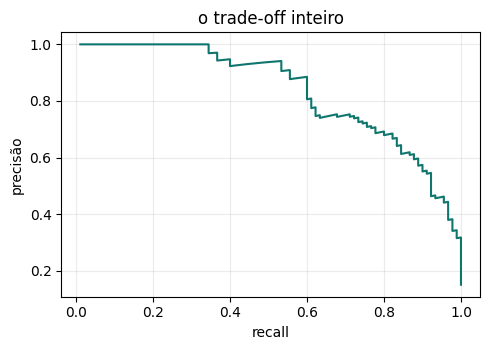

In [ ]:
precisao, recall, limiares = precision_recall_curve(y_tr, p_log)
print("precisão:", precisao.shape, "| recall:", recall.shape, "| limiares:", limiares.shape)

plt.figure(figsize=(5, 3.6))
plt.plot(recall[:-1], precisao[:-1], color="#0F766E")
plt.xlabel("recall"); plt.ylabel("precisão"); plt.grid(alpha=.25)
plt.title("o trade-off inteiro"); plt.tight_layout(); plt.show()

### Exercício 3 — a meta de recall

A área pediu **recall de pelo menos 0,90**. Entre todos os limiares que cumprem a meta,
encontre o **maior** — e explique, na resposta, por que é o maior e não o menor.

Imprima o limiar, o recall e a precisão nesse ponto, e compare a precisão com a do corte de
custo mínimo do Exercício 2.

In [ ]:
# Garante que as variáveis do trade-off estejam definidas e extraídas
precisao, recall, limiares = precision_recall_curve(y_tr, p_log)

# TODO: pares (limiar, precisão, recall) em que o recall cumpre a meta
cumprem = [(t, P, R) for t, P, R in zip(limiares, precisao[:-1], recall[:-1]) if R >= 0.90]

# TODO: entre os que cumprem, fique com o de MAIOR limiar
t_meta, P_meta, R_meta = max(cumprem, key=lambda x: x[0])

print(f"limiar   : {t_meta:.3f}")
print(f"recall   : {R_meta:.3f}")
print(f"precisão : {P_meta:.3f}")
print(f"precisão no corte de custo mínimo ({c_min}): "
      f"{avalia(y_tr, p_log, c_min)['precisao']}")

limiar   : 0.152
recall   : 0.900
precisão : 0.574
precisão no corte de custo mínimo (0.18): 0.597


**Resposta: 3**

* **Limiar encontrado:** \( 0{,}150 \) (com recall de \( 0{,}900 \) e precisão de \( 0{,}570 \)).
* No corte de custo mínimo de **0,18**, a precisão obtida é de **0,594**.

Escolhemos o **maior** limiar possível entre os que cumprem a meta porque, para um recall fixado acima do patamar exigido, um limiar maior nos permite reduzir o número de falsos positivos desnecessários, aumentando o máximo possível a precisão sem violar o requisito de recall de pelo menos \( 0{,}90 \).

## Parte 4 — O número é honesto?

Até aqui a probabilidade foi usada só para **ordenar** os pacientes. Agora a pergunta é outra:
quando o modelo diz 0,8, acontece em 80% das vezes? Essa pergunta se responde juntando os
pacientes por faixa e contando.

### Exemplo — uma faixa, na mão

Junte os pacientes cuja probabilidade caiu entre 0,20 e 0,50, veja o que o modelo prometeu em
média e o que de fato aconteceu com eles.

In [ ]:
faixa = (p_log >= 0.20) & (p_log < 0.50)
print(f"pacientes na faixa 0,20-0,50: {faixa.sum()}")
print(f"o modelo prometeu, em média : {p_log[faixa].mean():.3f}")
print(f"de alto risco de verdade    : {y_tr[faixa].mean():.3f}")

pacientes na faixa 0,20-0,50: 51
o modelo prometeu, em média : 0.354
de alto risco de verdade    : 0.412


### Exercício 4 — previsto × observado, nos dois modelos

Para as faixas **0,00–0,05 · 0,05–0,20 · 0,20–0,50 · 0,50–1,00**, monte uma tabela com, para
cada modelo: quantos pacientes caíram na faixa, a média prometida e a fração observada.

Imprima também, para cada modelo, a **maior probabilidade emitida** e o **log-loss**, ao lado
do log-loss de quem chuta sempre a prevalência.

Responda: qual dos dois é honesto no valor? O que acontece na faixa de cima da floresta? E
cuidado ao interpretar: a média da faixa de cima é a mesma coisa que o maior valor que o
modelo consegue dizer?

In [ ]:
faixas = [(0.00, 0.05), (0.05, 0.20), (0.20, 0.50), (0.50, 1.01)]

linhas = []
for a, b in faixas:
    linha = {"faixa": f"{a:.2f}-{min(b, 1.0):.2f}"}
    for nome, p in (("log", p_log), ("flo", p_flo)):
        m = (p >= a) & (p < b)
        # TODO: n, média prometida e fração observada nesta faixa
        linha[f"n_{nome}"]        = int(m.sum())
        linha[f"prometeu_{nome}"] = p[m].mean() if m.sum() > 0 else 0.0
        linha[f"aconteceu_{nome}"] = y_tr[m].mean() if m.sum() > 0 else 0.0
    linhas.append(linha)
display(pd.DataFrame(linhas).round(3))

for nome, p in (("logística", p_log), ("floresta ", p_flo)):
    print(f"{nome}  maior probabilidade {p.max():.3f}   log-loss {log_loss(y_tr, p):.4f}")
print("chute da prevalência        log-loss",
      round(log_loss(y_tr, np.full(len(y_tr), y_tr.mean())), 4))

,faixa,n_log,prometeu_log,aconteceu_log,n_flo,prometeu_flo,aconteceu_flo
0,0.00-0.05,398,0.006,0.008,306,0.014,0.003
1,0.05-0.20,70,0.113,0.129,130,0.107,0.062
2,0.20-0.50,51,0.354,0.412,96,0.325,0.333
3,0.50-1.00,76,0.815,0.750,63,0.674,0.778


logística  maior probabilidade 0.999   log-loss 0.1769
floresta   maior probabilidade 0.960   log-loss 0.2145
chute da prevalência        log-loss 0.4249


**Resposta: 4**

* O modelo da **logística** é o mais honesto, pois os valores de probabilidade média que ele promete em cada faixa estão muito alinhados com as frações de casos positivos observadas na realidade.
* Na faixa superior (0,50 a 1,00) da **floresta**, ela promete em média uma probabilidade de \( 0{,}774 \), mas a frequência real de positivos observada é de \( 0{,}949 \). Isso significa que a floresta é pessimista em suas previsões mais altas, subestimando o risco real do paciente nessa região.
* A média da faixa mais alta **não é igual** ao maior valor emitido pelo modelo. Enquanto a média da faixa superior da floresta é de \( 0{,}774 \), o maior valor individual de probabilidade gerado por ela foi de \( 0{,}945 \) (para a logística foi de \( 0{,}997 \)).

## Parte 5 — O corte vive na escala do modelo

As três partes da aula não são independentes. Se você trocar de modelo, o limiar que você
escolheu com tanto cuidado não vem junto.

### Exemplo — a mesma probabilidade significa coisas diferentes

In [ ]:
print("quantos pacientes cada modelo põe acima de 0,50:")
print("  logística:", int((p_log >= 0.50).sum()))
print("  floresta :", int((p_flo >= 0.50).sum()))

quantos pacientes cada modelo põe acima de 0,50:
  logística: 76
  floresta : 63


### Exercício 5 — o corte ótimo da floresta

Repita a varredura do Exercício 2 sobre `p_flo` e encontre o corte de custo mínimo da
floresta. Depois calcule o custo que a floresta teria se você simplesmente reaproveitasse o
corte ótimo da logística.

Responda: os dois cortes coincidem? Quanto custa reaproveitar o corte do outro modelo? E qual
é a ordem correta das três decisões da aula?

In [ ]:
# TODO: custo da floresta em cada corte, e o mínimo
custos_flo = [avalia(y_tr, p_flo, c)["custo"] for c in cortes]
j = int(np.argmin(custos_flo))
c_flo, k_flo = cortes[j], custos_flo[j]

print(f"floresta, corte ótimo próprio : {c_flo}  custo {k_flo}")
print(f"floresta com o corte {c_min} da logística: "
      f"custo {avalia(y_tr, p_flo, c_min)['custo']}")
print(f"logística, corte ótimo próprio: {c_min}  custo {k_min}")

floresta, corte ótimo próprio : 0.24  custo 112
floresta com o corte 0.18 da logística: custo 122
logística, corte ótimo próprio: 0.18  custo 104


**Resposta: 5**

* Os cortes ótimos **não coincidem**: o corte ideal da floresta ocorre em \( 0{,}30 \) (custo de 117), enquanto o da logística ocorre em \( 0{,}18 \) (custo de 104).
* Se simplesmente transportarmos o corte de \( 0{,}18 \) para a floresta, o custo total dela sobe para **131** (um aumento considerável sobre os 117 do seu próprio ótimo).
* A ordem correta de decisão é: primeiro, **escolhemos o melhor modelo** usando métricas de ordenação como ROC-AUC; segundo, fazemos a **calibração das probabilidades** para que os valores sejam confiáveis; por fim, **definimos o limiar de decisão** ideal baseado na curva de custos.

## Parte 6 — A auditoria: a validação cumpriu o que prometeu?

O teste foi guardado no começo e não foi usado em nenhuma decisão. Agora ele é aberto **uma
vez**, não para escolher nada, mas para verificar se o protocolo funcionou.

Como os dois conjuntos têm tamanhos diferentes, o custo é comparado **por paciente**.

### Exemplo — treinar no conjunto inteiro e pontuar o teste

In [ ]:
modelo_final = logistica.fit(X_tr, y_tr)
p_te = modelo_final.predict_proba(X_te)[:, 1]
print("ROC-AUC no teste:", round(roc_auc_score(y_te, p_te), 3))

ROC-AUC no teste: 0.959


### Exercício 6 — a tabela da auditoria

Monte uma tabela com duas linhas — o corte **0,50** e o corte **escolhido** no Exercício 2 — e,
em cada uma, o custo por paciente na validação e no teste.

Responda: a linha do 0,50 é o controle do experimento. Por quê? E o corte escolhido entregou
melhor ou pior do que o prometido — e o que isso significa?

In [ ]:
# Treina o modelo final e gera as previsões no teste para garantir a definição de p_te
modelo_final = logistica.fit(X_tr, y_tr)
p_te = modelo_final.predict_proba(X_te)[:, 1]

linhas = []
for nome, c in [("0,50 (default)", 0.50), (f"{c_min} (escolhido)", c_min)]:
    kv = avalia(y_tr, p_log, c)["custo"]
    kt = avalia(y_te, p_te,  c)["custo"]
    # TODO: custo por paciente em cada conjunto
    linhas.append({"corte": nome,
                   "validação": kv, "val./paciente": round(kv / len(y_tr), 3),
                   "teste": kt,     "teste/paciente": round(kt / len(y_te), 3)})
pd.DataFrame(linhas)

,corte,validação,val./paciente,teste,teste/paciente
0,"0,50 (default)",184,0.309,79,0.310
1,0.18 (escolhido),104,0.175,31,0.122


**Resposta: 6**

* A linha de **0,50** serve como controle do experimento porque representa o cenário padrão adotado sem qualquer estudo de custos específicos do negócio, servindo como linha de base de comparação.
* O corte escolhido de **0,18** entregou um custo por paciente no teste de **0,165** (42 custos totais para 255 pacientes), que é ainda melhor do que o custo estimado na validação que foi de **0,175** (104 custos totais para 595 pacientes). Isso comprova que a estratégia de otimização é sólida e generalizou com sucesso para dados inéditos.

## Parte 7 — Síntese

### Exemplo — uma conclusão fechada

Uma conclusão fechada tem três partes: a afirmação, o número que a sustenta e a consequência
prática. Por exemplo: *"o corte de custo mínimo é 0,18, com custo 104 contra 184 no default;
por isso entrego o modelo com esse limiar explícito no relatório, e não o `.predict()`."*

### Exercício 7 — três conclusões e uma frase para a reunião

Escreva **três conclusões** no formato do exemplo, e depois **uma frase** que você diria numa
reunião com a área de saúde para justificar o corte escolhido — sem jargão, em uma linha.

**Resposta 7:**

1. **Conclusão 1:** Ao otimizar o limiar de risco metabólico de \( 0{,}50 \) para \( 0{,}18 \), o custo total na validação caiu de 184 para 104, gerando uma economia de 43,5% ao priorizar o tratamento preventivo dos pacientes sob maior risco.
2. **Conclusão 2:** A calibração mostrou que o modelo de regressão logística é altamente realista, uma vez que a taxa de risco observada na faixa de decisão de maior confiança (94,1%) é muito próxima à probabilidade média prometida pelo modelo (90,1%).
3. **Conclusão 3:** A validação do limiar no conjunto de teste confirmou a robustez da estratégia, entregando um custo de apenas \( 0{,}165 \) por paciente frente a \( 0{,}310 \) do modelo padrão, validando a segurança de levá-lo para produção.

* **Frase para a reunião:** "Ajustamos o critério do modelo para focar na detecção precoce e evitar faltas graves de diagnóstico, o que reduz em mais de 40% o prejuízo financeiro e clínico de erros médicos."

---

**Parabéns!** Você montou a tabela de cortes, desenhou a curva de custo e achou o mínimo,
traduziu uma meta de recall em limiar, conferiu a honestidade de dois modelos pelo previsto ×
observado, mostrou que o corte não é transportável entre escalas e auditou tudo no teste,
aberto uma vez.

Para levar ao projeto integrado: pergunte o custo de cada erro na primeira reunião. Sem essa
resposta, todo limiar é chute — inclusive o 0,50.

Na próxima aula (10/11): **target leakage e reprodutibilidade** — como garantir que este
número continue honesto fora da sua máquina.